---
title: Solving LinkedIn Tango by Linear Optimization
short_title: How to Solve Tango
date: 2025-03-08
---

![Tango Banner](../assets/how-to-solve/tango/banner.jpg)

<a href="https://mybinder.org/v2/gh/rodrigo-cl-porto/LinkedIn-Games-Linear-Optimization-Solvers/binder?urlpath=lab/tree/notebooks/tango.ipynb">
  <img src="https://mybinder.org/badge_logo.svg" alt="Launch Binder" width="20%" >
</a>

# How to Play Tango

:::{figure} ../assets/how-to-solve/tango/example.mp4
:label: tango-example
:alt: A Tango Example
:align: center
:width: 60%
Example of a Tango minigame board. _Source: [LinkedIn Tango](https://www.linkedin.com/games/tango/)_
:::

The Tango's board is a 6 $\times$ 6 game board with some squares already filled by moons 🌙 and suns ☀️ symbols, and which can have some pairs of squares with an `=` sign or `×` sign in-between.

Objective
: Fill all the squares on the board with moons 🌙 and suns ☀️.

Rules
: The number of moons and suns in each row and column must be the same;
: There cannot be more than 2 moons or 2 suns in a row, either in a row or column;
: Squares separated by the `=` sign must contain the same symbol;
: Squares separated by the `×` sign must contain opposite symbols.

# Problem Modeling

In order to model our LOP, it will be necessary to define the following elements:

- **Ranges**
- **Sets**
- **Decision variables**
- **Parameters**
- **Objective function**
- **Constraints**

## Ranges

$I = \{1, \cdots, n\}$
: The row range, where $n$ is the total number of rows in the grid.

$J = \{1, \cdots, m\}$
: The column range, where $n$ is the total number of columns in the grid.

## Sets

In addition to the row and column ranges, it will be necessary to consider the sets of pairs of squares with `=` and `×` signs, plus the set of squares already filled with a sun or moon symbol. Therefore, there will be:

$S = I \times J = \{(i, j) \mid \forall i \in I, \forall j \in J\}$
: Set of all board squares $(i, j)$, which is simply the Cartesian product of the ranges $I$ and $J$.

$M = \{(v, w) \mid v, w \in S, v \ne w\}$
: Set of pairs of squares separated by `=`.

$O = \{(v, w) \mid v, w \in S, v \ne w\}$
: Set of pairs of squares separated by `×`.

$K \subset S$
: Set of squares with an already filled symbol.

## Decision Variables

The decision variables will be binary, since Tango only uses two symbols. Therefore, the LOP is actually a **BLOP**:

$x_{ij} \in \B, \quad \forall (i,j) \in S$
: $x_{ij} = 1$, if the square in row $i$ and column $j$ will be filled with a 🌙;
: $x_{ij} = 0$, if the same square will be filled with a ☀️.

:::{note}
The choice to represent the moon by 1 and the sun by 0 is purely arbitrary. (Actually, the fact that both the sun and 0 are round ended up influencing this decision). Therefore, there is nothing to prevent the choice from having been the exact opposite (with 0 = 🌙 and 1 = ☀️), since the choice of which number to represent which symbol does not influence the logical structure of the model, only the interpretation of its result.
:::

## Parameters

In Tango, there may be some cells that already come with a predefined symbol: sun or moon. As the set of parameters in our model, there will be:

$k_{ij} \in \B, \quad \forall (i,j) \in K$
: $k_{ij} = 1$, if the square in row $i$ and column $j$ is already filled with a 🌙;
: $k_{ij} = 0$, if the same square is already filled with a ☀️.

## Objective Function

Here, our objective is not to optimize a function, but rather to find a solution that fulfills all the rules of the game. Therefore, a Tango BLOP is not an optimization problem, but a **feasibility problem**. Thus, the objective function will be to minimize (or maximize, it doesn't matter) an arbitrary constant $C$.

$$\text{Min} \quad C$$

## Constraints

With the previous elements well defined, we can translate the rules of the game to our BLOP as follows:

Binarity Constraints
: First, we must define that all decision variables in our problem are binary variables, that is, they only accept 0 and 1 as the only possible values.
: $$x_{ij} \in \B, \quad \forall (i,j) \in S$$

Equal-Moons-Suns-Per-Row Constraints
: Since the number of suns and moons for each row must be equal, the sum of $x_{ij}$ belonging to a row $i$ must equal the half of total columns, therefore 3. Since there are 6 rows, the model will have 6 of these constraints.
: $$\sum_{j=1}^{m}{x_{ij}}=\frac{m}{2}, \quad \forall i \in I$$

Equal-Moons-Suns-Per-Column Constraints
: The same logic applies to the columns. Therefore, there are 6 more constraints.
: $$\sum_{i=1}^{n}{x_{ij}}=\frac{n}{2}, \quad \forall j \in J$$

No-Three-Consecutive-Moons-Per-Row Constraints
: Since the 3 moons in a row cannot be next to each other, it means that the sum of three consecutive $x_{ij}$ in a row must be less than or equal to 2.
: $$x_{ij} + x_{i,j+1} + x_{i,j+2} \le 2, \quad \forall i \in I, \forall j \in \{1, \cdots, m-2\}$$

No-Three-Consecutive-Moons-Per-Column Constraints
: And the same logic applies to the columns.
: $$x_{ij} + x_{i+1,j} + x_{i+2,j} \le 2, \quad \forall i \in \{1, \cdots, n-2\}, \forall j \in J$$

No-Three-Consecutive-Suns-Per-Row Constraints
: Similarly, since there cannot be 3 consecutive suns in a row, the sum of 3 subsequent $x_{ij}$ in a row i must be greater than or equal to 1.
: $$x_{ij} + x_{i,j+1} + x_{i,j+2} \ge 1, \quad \forall i \in I, \forall j \in \{1, \cdots,m-2\}$$

No-Three-Consecutive-Suns-Per-Column Constraints
: And the same logic applies to the columns.
: $$x_{ij} + x_{i+1,j} + x_{i+2,j} \ge 1, \quad \forall i \in \{1, \cdots, n-2\}, \forall j \in J$$

Already-Filled-squares Constraints
: For each square that already has a pre-established figure, it is necessary to impose that $x_{ij}$ is equal to 1 or 0, depending on whether the figure is a moon or a sun, respectively.
: $$x_{ij} = k_{ij}, \quad \forall k_{ij} \in K$$

Matching-Pairs Constraints
: For each pair of adjacent cells that contains the `=` sign between them, it is necessary to impose the constraint that the values $x_{ij}$ of that pair are equal, which is the same as saying that the difference between the values $x_{ij}$ of that pair must be equal to 0.
: $$x_v - x_w = 0, \quad \forall \{v,w\} \in M$$

Opposite-Pairs Constraints
: Finally, for each pair of adjacent cells that contains the sign `×` between them, it is necessary to impose the constraint that the values $x_{ij}$ of this pair are different, which is the same as saying that the sum of the values $x_{ij}$ of this pair must be equal to 1.
: $$x_v + x_w = 1, \quad \forall \{v,w\} \in O$$

# Abstract Model

Up to this point, the formulas created have been based on the premise that every Tango minigame will have 6 rows and 6 columns, which is indeed the case. However, in order to create a more generalized abstract model, we can admit that this will not always be a certainty, and therefore there is a possibility that the number of rows and columns will vary from game to game. Due to the restriction that the number of moons and suns for each row and column must be equal, it must be assumed that the total number of rows and columns are even numbers, that is, $n \mod 2 \equiv 0$ and $m \mod 2 \equiv 0$.

Thus, having raised these points, the abstract model of the Tango minigame is formulated as follows:

:::{math}
:enumerated: false
\text{Min} \quad C
:::

$$
\begin{array}{lll}
    \text{S.t.:} & \\
    & \sum_{j \in J}{x_{ij}} = m/2,         & \quad \forall i \in I \\
    & \sum_{i \in I}{x_{ij}} = n/2,         & \quad \forall j \in J \\
    & x_{ij} + x_{ij+1} + x_{ij+2} \le 2,   & \quad \forall i \in I, \forall j \in J \backslash \{m-1,m\} \\
    & x_{ij} + x_{i+1,j} + x_{i+2,j} \le 2, & \quad \forall i \in I \backslash \{n-1,n\}, \forall j \in J \\
    & x_{ij} + x_{ij+1} + x_{ij+2} \ge 1,   & \quad \forall i \in I, \forall j \in J \backslash \{m-1,m\} \\
    & x_{ij} + x_{i+1,j} + x_{i+2,j} \ge 1, & \quad \forall i \in I \backslash \{n-1,n\}, \forall j \in J \\
    & x_{ij} = k_{ij},                      & \quad \forall k_{ij} \in K \\
    & x_{ij} - x_{rs} = 0,                  & \quad \forall ((i,j),(r,s)) \in N \\
    & x_{ij} + x_{rs} = 1,                  & \quad \forall ((i,j),(r,s)) \in M \\
    & x_{ij} \in \B,                        & \quad \forall (i,j) \in S
\end{array}
$$

# Concrete Model

The concrete model was built based on the Tango minigame No. 151

:::{figure} ../assets/how-to-solve/tango/problem.png
:label: tango-problem
:alt: Tango No. 151
:align: center
:width: 60%
Tango No. 151, March 7{sup}`th`, 2025. _Source: [LinkedIn Tango](https://www.linkedin.com/games/tango/)_
:::

:::{math}
:enumerated: false
\text{Min} \quad 0
:::

S.t.:

Equal-Moons-Suns-Per-Row Constraints
: $x_{11} + x_{12} + x_{13} + x_{14} + x_{15} + x_{16} = 3$ {sub}`(_Row 1_)`
: $x_{21} + x_{22} + x_{23} + x_{24} + x_{25} + x_{26} = 3$ {sub}`(_Row 2_)`
: $x_{31} + x_{32} + x_{33} + x_{34} + x_{35} + x_{36} = 3$ {sub}`(_Row 3_)`
: $x_{41} + x_{42} + x_{43} + x_{44} + x_{45} + x_{46} = 3$ {sub}`(_Row 4_)`
: $x_{51} + x_{52} + x_{53} + x_{54} + x_{55} + x_{56} = 3$ {sub}`(_Row 5_)`
: $x_{61} + x_{62} + x_{63} + x_{64} + x_{65} + x_{66} = 3$ {sub}`(_Row 6_)`

Equal-Moons-Suns-Per-Column Constraints
: $x_{11} + x_{21} + x_{31} + x_{41} + x_{51} + x_{61} = 3$ {sub}`(_Column 1_)`
: $x_{12} + x_{22} + x_{32} + x_{42} + x_{52} + x_{62} = 3$ {sub}`(_Column 2_)`
: $x_{13} + x_{23} + x_{33} + x_{43} + x_{53} + x_{63} = 3$ {sub}`(_Column 3_)`
: $x_{14} + x_{24} + x_{34} + x_{44} + x_{54} + x_{64} = 3$ {sub}`(_Column 4_)`
: $x_{15} + x_{25} + x_{35} + x_{45} + x_{55} + x_{65} = 3$ {sub}`(_Column 5_)`
: $x_{16} + x_{26} + x_{36} + x_{46} + x_{56} + x_{66} = 3$ {sub}`(_Column 6_)`

No-Three-Consecutive-Moons-Per-Row Constraints
: $x_{11} + x_{21} + x_{31} \le 2$ {sub}`(_Row 1_)`
: $x_{12} + x_{13} + x_{14} \le 2$ {sub}`(_Row 1_)`
: $x_{13} + x_{14} + x_{15} \le 2$ {sub}`(_Row 1_)`
: $x_{14} + x_{15} + x_{16} \le 2$ {sub}`(_Row 1_)`
: $x_{21} + x_{22} + x_{23} \le 2$ {sub}`(_Row 2_)`
: $x_{22} + x_{23} + x_{24} \le 2$ {sub}`(_Row 2_)`
: $x_{23} + x_{24} + x_{25} \le 2$ {sub}`(_Row 2_)`
: $x_{24} + x_{25} + x_{26} \le 2$ {sub}`(_Row 2_)`
: $x_{31} + x_{32} + x_{33} \le 2$ {sub}`(_Row 3_)`
: $x_{32} + x_{33} + x_{34} \le 2$ {sub}`(_Row 3_)`
: $x_{33} + x_{34} + x_{35} \le 2$ {sub}`(_Row 3_)`
: $x_{34} + x_{35} + x_{36} \le 2$ {sub}`(_Row 3_)`
: $x_{41} + x_{42} + x_{43} \le 2$ {sub}`(_Row 4_)`
: $x_{42} + x_{43} + x_{44} \le 2$ {sub}`(_Row 4_)`
: $x_{43} + x_{44} + x_{45} \le 2$ {sub}`(_Row 4_)`
: $x_{44} + x_{45} + x_{46} \le 2$ {sub}`(_Row 4_)`
: $x_{51} + x_{52} + x_{53} \le 2$ {sub}`(_Row 5_)`
: $x_{52} + x_{53} + x_{54} \le 2$ {sub}`(_Row 5_)`
: $x_{53} + x_{54} + x_{55} \le 2$ {sub}`(_Row 5_)`
: $x_{54} + x_{55} + x_{56} \le 2$ {sub}`(_Row 5_)`
: $x_{61} + x_{62} + x_{63} \le 2$ {sub}`(_Row 6_)`
: $x_{62} + x_{63} + x_{64} \le 2$ {sub}`(_Row 6_)`
: $x_{63} + x_{64} + x_{65} \le 2$ {sub}`(_Row 6_)`
: $x_{64} + x_{65} + x_{66} \le 2$ {sub}`(_Row 6_)`

No-Three-Consecutive-Moons-Per-Column Constraints
: $x_{11} + x_{21} + x_{31} \le 2$ {sub}`(_Column 1_)`
: $x_{21} + x_{31} + x_{41} \le 2$ {sub}`(_Column 1_)`
: $x_{31} + x_{41} + x_{51} \le 2$ {sub}`(_Column 1_)`
: $x_{41} + x_{51} + x_{61} \le 2$ {sub}`(_Column 1_)`
: $x_{12} + x_{22} + x_{32} \le 2$ {sub}`(_Column 2_)`
: $x_{22} + x_{32} + x_{42} \le 2$ {sub}`(_Column 2_)`
: $x_{32} + x_{42} + x_{52} \le 2$ {sub}`(_Column 2_)`
: $x_{42} + x_{52} + x_{62} \le 2$ {sub}`(_Column 2_)`
: $x_{13} + x_{23} + x_{33} \le 2$ {sub}`(_Column 3_)`
: $x_{23} + x_{33} + x_{43} \le 2$ {sub}`(_Column 3_)`
: $x_{33} + x_{43} + x_{53} \le 2$ {sub}`(_Column 3_)`
: $x_{43} + x_{53} + x_{63} \le 2$ {sub}`(_Column 3_)`
: $x_{14} + x_{24} + x_{34} \le 2$ {sub}`(_Column 4_)`
: $x_{24} + x_{34} + x_{44} \le 2$ {sub}`(_Column 4_)`
: $x_{34} + x_{44} + x_{54} \le 2$ {sub}`(_Column 4_)`
: $x_{44} + x_{54} + x_{64} \le 2$ {sub}`(_Column 4_)`
: $x_{15} + x_{25} + x_{35} \le 2$ {sub}`(_Column 5_)`
: $x_{25} + x_{35} + x_{45} \le 2$ {sub}`(_Column 5_)`
: $x_{35} + x_{45} + x_{55} \le 2$ {sub}`(_Column 5_)`
: $x_{45} + x_{55} + x_{65} \le 2$ {sub}`(_Column 5_)`
: $x_{16} + x_{26} + x_{36} \le 2$ {sub}`(_Column 6_)`
: $x_{26} + x_{36} + x_{46} \le 2$ {sub}`(_Column 6_)`
: $x_{36} + x_{46} + x_{56} \le 2$ {sub}`(_Column 6_)`
: $x_{46} + x_{56} + x_{66} \le 2$ {sub}`(_Column 6_)`

No-Three-Consecutive-Suns-Per-Row Constraints
: $x_{11} + x_{21} + x_{31} \ge 1$ {sub}`(_Row 1_)`
: $x_{12} + x_{13} + x_{14} \ge 1$ {sub}`(_Row 1_)`
: $x_{13} + x_{14} + x_{15} \ge 1$ {sub}`(_Row 1_)`
: $x_{14} + x_{15} + x_{16} \ge 1$ {sub}`(_Row 1_)`
: $x_{21} + x_{22} + x_{23} \ge 1$ {sub}`(_Row 2_)`
: $x_{22} + x_{23} + x_{24} \ge 1$ {sub}`(_Row 2_)`
: $x_{23} + x_{24} + x_{25} \ge 1$ {sub}`(_Row 2_)`
: $x_{24} + x_{25} + x_{26} \ge 1$ {sub}`(_Row 2_)`
: $x_{31} + x_{32} + x_{33} \ge 1$ {sub}`(_Row 3_)`
: $x_{32} + x_{33} + x_{34} \ge 1$ {sub}`(_Row 3_)`
: $x_{33} + x_{34} + x_{35} \ge 1$ {sub}`(_Row 3_)`
: $x_{34} + x_{35} + x_{36} \ge 1$ {sub}`(_Row 3_)`
: $x_{41} + x_{42} + x_{43} \ge 1$ {sub}`(_Row 4_)`
: $x_{42} + x_{43} + x_{44} \ge 1$ {sub}`(_Row 4_)`
: $x_{43} + x_{44} + x_{45} \ge 1$ {sub}`(_Row 4_)`
: $x_{44} + x_{45} + x_{46} \ge 1$ {sub}`(_Row 4_)`
: $x_{51} + x_{52} + x_{53} \ge 1$ {sub}`(_Row 5_)`
: $x_{52} + x_{53} + x_{54} \ge 1$ {sub}`(_Row 5_)`
: $x_{53} + x_{54} + x_{55} \ge 1$ {sub}`(_Row 5_)`
: $x_{54} + x_{55} + x_{56} \ge 1$ {sub}`(_Row 5_)`
: $x_{61} + x_{62} + x_{63} \ge 1$ {sub}`(_Row 6_)`
: $x_{62} + x_{63} + x_{64} \ge 1$ {sub}`(_Row 6_)`
: $x_{63} + x_{64} + x_{65} \ge 1$ {sub}`(_Row 6_)`
: $x_{64} + x_{65} + x_{66} \ge 1$ {sub}`(_Row 6_)`

No-Three-Consecutive-Suns-Per-Column Constraints
: $x_{11} + x_{21} + x_{31} \ge 1$ {sub}`(_Column 1_)`
: $x_{21} + x_{31} + x_{41} \ge 1$ {sub}`(_Column 1_)`
: $x_{31} + x_{41} + x_{51} \ge 1$ {sub}`(_Column 1_)`
: $x_{41} + x_{51} + x_{61} \ge 1$ {sub}`(_Column 1_)`
: $x_{12} + x_{22} + x_{32} \ge 1$ {sub}`(_Column 2_)`
: $x_{22} + x_{32} + x_{42} \ge 1$ {sub}`(_Column 2_)`
: $x_{32} + x_{42} + x_{52} \ge 1$ {sub}`(_Column 2_)`
: $x_{42} + x_{52} + x_{62} \ge 1$ {sub}`(_Column 2_)`
: $x_{13} + x_{23} + x_{33} \ge 1$ {sub}`(_Column 3_)`
: $x_{23} + x_{33} + x_{43} \ge 1$ {sub}`(_Column 3_)`
: $x_{33} + x_{43} + x_{53} \ge 1$ {sub}`(_Column 3_)`
: $x_{43} + x_{53} + x_{63} \ge 1$ {sub}`(_Column 3_)`
: $x_{14} + x_{24} + x_{34} \ge 1$ {sub}`(_Column 4_)`
: $x_{24} + x_{34} + x_{44} \ge 1$ {sub}`(_Column 4_)`
: $x_{34} + x_{44} + x_{54} \ge 1$ {sub}`(_Column 4_)`
: $x_{44} + x_{54} + x_{64} \ge 1$ {sub}`(_Column 4_)`
: $x_{15} + x_{25} + x_{35} \ge 1$ {sub}`(_Column 5_)`
: $x_{25} + x_{35} + x_{45} \ge 1$ {sub}`(_Column 5_)`
: $x_{35} + x_{45} + x_{55} \ge 1$ {sub}`(_Column 5_)`
: $x_{45} + x_{55} + x_{65} \ge 1$ {sub}`(_Column 5_)`
: $x_{16} + x_{26} + x_{36} \ge 1$ {sub}`(_Column 6_)`
: $x_{26} + x_{36} + x_{46} \ge 1$ {sub}`(_Column 6_)`
: $x_{36} + x_{46} + x_{56} \ge 1$ {sub}`(_Column 6_)`
: $x_{46} + x_{56} + x_{66} \ge 1$ {sub}`(_Column 6_)`

Matching-Pairs Constraints
: $x_{23} - x_{24} = 0$
: $x_{21} - x_{31} = 0$
: $x_{23} - x_{33} = 0$
: $x_{26} - x_{36} = 0$
: $x_{41} - x_{42} = 0$
: $x_{63} - x_{64} = 0$

Opposite-Pairs Constraints
: $x_{24} + x_{34} = 1$
: $x_{33} + x_{34} = 1$
: $x_{36} + x_{46} = 1$
: $x_{45} + x_{46} = 1$

Already-Filled-squares Constraints
: $x_{12} = 1$
: $x_{15} = 1$
: $x_{51} = 0$
: $x_{55} = 1$

Binarity Constraints
: $x_{12} \in \B$
: $x_{13} \in \B$
: $x_{14} \in \B$
: $x_{15} \in \B$
: $x_{16} \in \B$
: $x_{21} \in \B$
: $x_{22} \in \B$
: $x_{23} \in \B$
: $x_{24} \in \B$
: $x_{25} \in \B$
: $x_{26} \in \B$
: $x_{31} \in \B$
: $x_{32} \in \B$
: $x_{33} \in \B$
: $x_{34} \in \B$
: $x_{35} \in \B$
: $x_{36} \in \B$
: $x_{41} \in \B$
: $x_{42} \in \B$
: $x_{43} \in \B$
: $x_{44} \in \B$
: $x_{45} \in \B$
: $x_{46} \in \B$
: $x_{51} \in \B$
: $x_{52} \in \B$
: $x_{53} \in \B$
: $x_{54} \in \B$
: $x_{55} \in \B$
: $x_{56} \in \B$
: $x_{61} \in \B$
: $x_{62} \in \B$
: $x_{63} \in \B$
: $x_{64} \in \B$
: $x_{65} \in \B$
: $x_{66} \in \B$

# Solving Tango

In order to solve the presented game, the `linkedin-games` library counts on `Tango` class, that implements the Tango game and its constraints, as well as methods to solve it and visualize the solution.

To instantiate the game, it is necessary to provide three sets of inputs regarding the game in question:

`filled_squares`
: A dictionary of `(row, column): 0 | 1` representing the pre-filled squares.

`matching_pairs`
: A tuple of pairs of squares separated by the `=` symbol.

`opposite_pairs`
: A tuple of pairs of squares separated by the `×` symbol.

In [1]:
from linkedin_games import Tango

# Solving Tango No. 151

matching_pairs = [
    ((2,3), (2,4)), ((2,1), (3,1)), ((2,3), (3,3)),
    ((2,6), (3,6)), ((4,1), (4,2)), ((6,3), (6,4)),
]
opposite_pairs = [((2,4), (3,4)), ((3,1), (4,1)), ((3,3), (3,4)), ((3,6), (4,6)), ((4,5), (4,6))]
filled_squares = {(1, 2): 1, (1, 5): 1, (5, 2): 0, (5, 5): 1}
tango = Tango(filled_squares, matching_pairs, opposite_pairs)

The `solve()` method calls a modeler to structure the Linear Optimization logic behind the Tango's game before solving it.

:::{tip}
If the `verbose` argument is enabled, the game solution will be printed on the screen.
:::

:::{literalinclude} ../../src/linkedin_games/tango/_opt_modeler.py
:caption: Creating the model with Pyomo components
:label: tango-opt-model
:lang: python
:linenos:
:::

The method `display()`, in its turn, calls a renderer to plot the Tango's board.

:::{literalinclude} ../../src/linkedin_games/tango/_renderer.py
:caption: The Tango's renderer.
:label: tango-renderer
:lang: python
:linenos:
:::

So to solve the game and display its results, just call the public methods `solve()` and `display()`, at this order.

Game solved successfully!


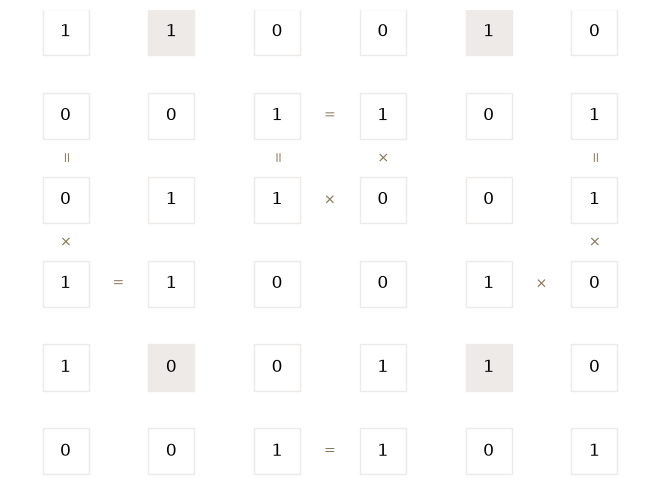

In [2]:
tango.solve().display()

As expected, the image result matches the solution of Tango No. 151

:::{figure} ../assets/how-to-solve/tango/solution.png
:label: tango-solution
:alt: Solution of Tango No. 151
:align: center
:width: 60%
Solution of Tango No. 151, March 7{sup}`th`, 2025. _Source: [LinkedIn Tango](https://www.linkedin.com/games/tango/)_
:::

---